# Titanic Exploratory Data Analysis (EDA)

## Project Objective
To analyze the Titanic passenger dataset using Python and Pandas.

## Research Questions

1. Did female passengers have a higher survival rate than male passengers?
2. Did passenger class affect the survival rate?
3. Which age group had the highest survival rate?

In [ ]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

df = sns.load_dataset("titanic")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [ ]:

print("Dataset Shape:", df.shape)


Dataset Shape: (891, 15)


In [ ]:

df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:

df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [ ]:

df.describe()


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)


Missing Values in Each Column:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [ ]:

df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"]
    .transform("median")
)

print("Missing Age Values:", df["age"].isnull().sum())


Missing Age Values: 0


In [ ]:

df = df.drop(columns=["deck"])

print("Deck column removed successfully!")


Deck column removed successfully!


In [ ]:

df["embarked"] = df["embarked"].fillna(
    df["embarked"].mode()[0]
)

print("Missing Embarked Values:", df["embarked"].isnull().sum())


Missing Embarked Values: 0


In [ ]:

print(df.isnull().sum())


survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64


In [ ]:

df["embark_town"] = df["embark_town"].fillna(
    df["embark_town"].mode()[0]
)

print(df.isnull().sum())


survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


In [ ]:

print("Duplicate Rows:", df.duplicated().sum())


Duplicate Rows: 118


In [ ]:

duplicate_data = df[df.duplicated()]

print("Duplicate Records:")
display(duplicate_data.head(10))


Duplicate Records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
47,1,3,female,21.5,0,0,7.7500,Q,Third,woman,False,Queenstown,yes,True
64,0,1,male,40.0,0,0,27.7208,C,First,man,True,Cherbourg,no,True
76,0,3,male,25.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
77,0,3,male,25.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
87,0,3,male,25.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
95,0,3,male,25.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
101,0,3,male,25.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
121,0,3,male,25.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
133,1,2,female,29.0,1,0,26.0000,S,Second,woman,False,Southampton,yes,False
173,0,3,male,21.0,0,0,7.9250,S,Third,man,True,Southampton,no,True


In [ ]:

print(df.dtypes)


survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
embark_town      object
alive            object
alone              bool
dtype: object


In [ ]:

survival_by_gender = df.groupby("sex")["survived"].mean()

print(survival_by_gender.round(2))


sex
female    0.74
male      0.19
Name: survived, dtype: float64


In [ ]:

print("Survival Rate in Percentage:")

print((survival_by_gender * 100).round(2))


Survival Rate in Percentage:
sex
female    74.20
male      18.89
Name: survived, dtype: float64



### Finding 1: Gender and Survival

Female passengers had a survival rate of 74.20%,
whereas male passengers had a survival rate of 18.89%.

This shows that female passengers had a higher
survival rate in the Titanic dataset.


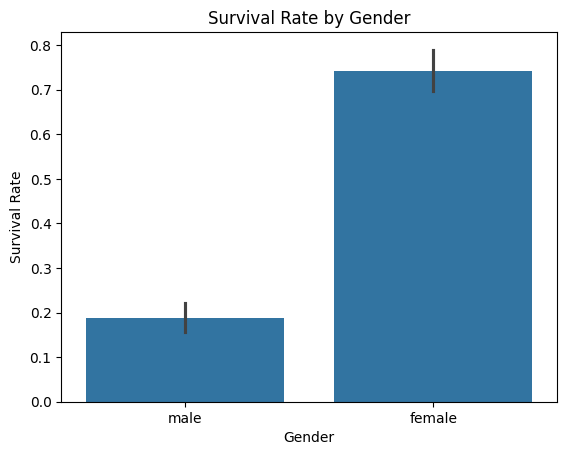

In [ ]:

sns.barplot(data=df, x="sex", y="survived")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.show()


In [ ]:

survival_by_class = df.groupby("pclass")["survived"].mean()

print(survival_by_class.round(2))


pclass
1    0.63
2    0.47
3    0.24
Name: survived, dtype: float64


In [ ]:

print("Survival Rate by Passenger Class:")

print((survival_by_class * 100).round(2))


Survival Rate by Passenger Class:
pclass
1    62.96
2    47.28
3    24.24
Name: survived, dtype: float64



### Finding 2: Passenger Class and Survival

First-class passengers had the highest survival rate
of 62.96%, followed by second-class passengers at
47.28% and third-class passengers at 24.24%.

This indicates that passenger class was associated
with survival differences in the Titanic dataset.


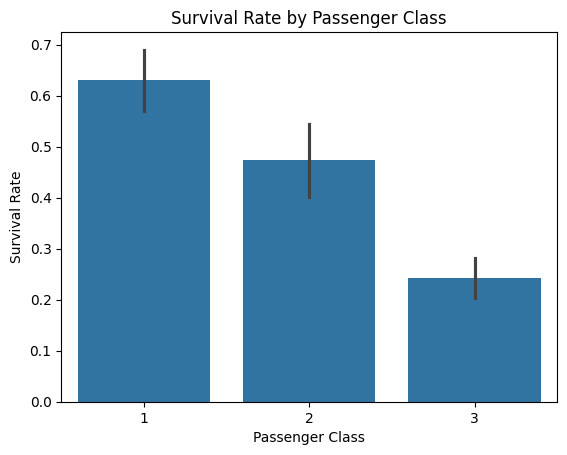

In [ ]:

sns.barplot(data=df, x="pclass", y="survived")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()


In [ ]:

df["age_band"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 40, 60, 100],
    labels=["Child", "Teen", "Adult",
            "Middle-aged", "Senior"],
    include_lowest=True
)

print(df[["age", "age_band"]].head(10))


    age     age_band
0  22.0        Adult
1  38.0        Adult
2  26.0        Adult
3  35.0        Adult
4  35.0        Adult
5  25.0        Adult
6  54.0  Middle-aged
7   2.0        Child
8  27.0        Adult
9  14.0         Teen


In [ ]:

survival_by_age = df.groupby(
    "age_band", observed=True
)["survived"].mean()

print(survival_by_age.round(2))


age_band
Child          0.58
Teen           0.43
Adult          0.36
Middle-aged    0.39
Senior         0.23
Name: survived, dtype: float64


In [ ]:

print("Survival Rate by Age Group:")

print((survival_by_age * 100).round(2))


Survival Rate by Age Group:
age_band
Child          57.97
Teen           42.86
Adult          36.05
Middle-aged    39.06
Senior         22.73
Name: survived, dtype: float64



### Finding 3: Age Group and Survival

Children had the highest survival rate at 57.97%,
followed by teenagers at 42.86%, adults at 36.05%,
middle-aged passengers at 39.06%, and seniors at 22.73%.

This shows that survival rates differed across age groups.


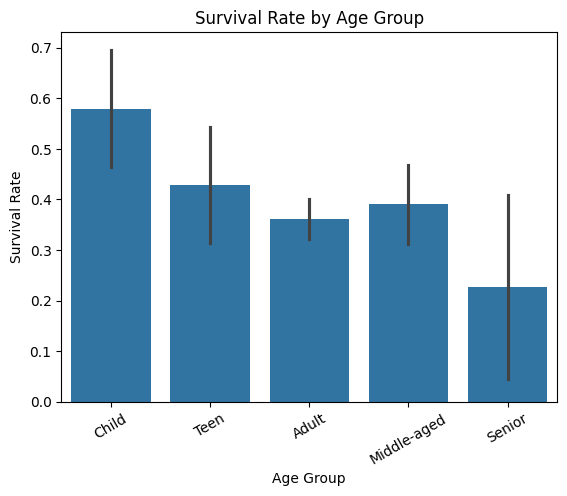

In [ ]:

sns.barplot(
    data=df,
    x="age_band",
    y="survived"
)

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")
plt.xticks(rotation=30)
plt.show()


In [ ]:

print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Final Dataset Shape: (891, 15)

Missing Values:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
age_band       0
dtype: int64

Duplicate Rows:
118
